# **Taller 2: YOLO26 — cómo funciona, entrenamiento y detección de rostros y expresiones faciales**

**Al terminar podrás:**
1. Explicar **cómo decide YOLO** qué objetos mostrar (confianza y cajas repetidas).
2. Combinar **OpenCV y YOLO**: limpiar la imagen antes del modelo y procesar los resultados después.
3. **Entrenar YOLO26 con tus propias imágenes** (*fine-tuning*), configurar sus **hiperparámetros** y evaluar si funciona bien.
4. Detectar **rostros con sus puntos clave** y reconocer la **expresión facial** de cada persona.

**Autor:** David Alexander Salazar

**Antes de empezar (Colab gratuito):**
1. `Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU` (para entrenar).
2. Crea una cuenta en [Roboflow](https://roboflow.com/) y copia tu *Private API Key* (`Settings → API Keys`).
3. En Colab, abre el panel **Secretos** (ícono de llave), crea `ROBOFLOW_API_KEY` con esa clave y activa *Acceso al notebook*.

> Si no hay GPU disponible, el notebook entrena en modo reducido en CPU (sirve para ver el proceso, no para obtener buenas métricas).

# **0. Configuración**

In [1]:
%pip install -q -U ultralytics lap roboflow

# OpenCV 5: CascadeClassifier solo en contrib
import importlib.metadata as metadata, os, subprocess, sys
try:
    version_cv = '==' + metadata.version('opencv-python')
except metadata.PackageNotFoundError:
    version_cv = ''
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', '--force-reinstall',
                f'opencv-contrib-python-headless{version_cv}'], check=True)

# cv2 ya importado sin contrib -> reiniciar kernel (una sola vez)
cv2_cargado = sys.modules.get('cv2')
if cv2_cargado is not None and not hasattr(cv2_cargado, 'CascadeClassifier') and not os.path.exists('/tmp/.reinicio_opencv'):
    open('/tmp/.reinicio_opencv', 'w').close()
    print('Reiniciando la sesión... al reconectar, ejecuta de nuevo desde esta celda.')
    os.kill(os.getpid(), 9)
print('Instalación lista.')

Instalación lista.


In [2]:
import os, sys, glob, time, shutil, subprocess, urllib.request
import yaml
from base64 import b64encode, b64decode
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ipywidgets as widgets
from ipywidgets import interact
from IPython.display import HTML, display, Image as IPyImage
from PIL import Image
from ultralytics import YOLO

HOME = os.getcwd()
GPU = torch.cuda.is_available()
DEVICE = 0 if GPU else 'cpu'
CFG = (dict(epochs=15, imgsz=640, batch=16, fraction=1.0) if GPU
       else dict(epochs=2, imgsz=320, batch=8, fraction=0.25))    # CPU: modo reducido
print('OpenCV', cv2.__version__, '| dispositivo:', torch.cuda.get_device_name(0) if GPU else 'CPU (sin GPU)')
if not hasattr(cv2, 'CascadeClassifier'):
    print('AVISO: OpenCV sin CascadeClassifier. Reinicia la sesión y ejecuta desde la Sección 0.')

os.makedirs('material', exist_ok=True)
os.makedirs('output', exist_ok=True)
VIDEOS_URL = 'https://github.com/intel-iot-devkit/sample-videos/raw/master/'
DESCARGAS = {
    'autos':      VIDEOS_URL + 'car-detection.mp4',
    'frutas':     VIDEOS_URL + 'fruit-and-vegetable-detection.mp4',
    'rostros':    VIDEOS_URL + 'face-demographics-walking.mp4',
    'emociones':  VIDEOS_URL + 'head-pose-face-detection-female-and-male.mp4',
    'bus':        'https://ultralytics.com/images/bus.jpg',
    'yolo_face':  'https://github.com/akanametov/yolo-face/releases/download/1.0.0/yolo26n-face.pt',
    'expresion':  'https://github.com/opencv/opencv_zoo/raw/main/models/facial_expression_recognition/facial_expression_recognition_mobilefacenet_2022july.onnx',
    'haar':       'https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml',
}
ARCHIVOS = {}
for nombre, url in DESCARGAS.items():
    ruta = 'material/' + url.split('/')[-1]
    if not os.path.exists(ruta):
        urllib.request.urlretrieve(url, ruta)
    ARCHIVOS[nombre] = ruta
print('Material listo:', list(ARCHIVOS))

# --- utilidades ---
def leer_frame(video, n, tam=None):
    """Frame n del video (BGR)."""
    cap = cv2.VideoCapture(video)
    cap.set(cv2.CAP_PROP_POS_FRAMES, n)
    ok, frame = cap.read()
    cap.release()
    return cv2.resize(frame, tam) if tam else frame

def mostrar(imagenes, titulos=None, cols=3, ancho=16):
    """Grilla de imágenes BGR o en gris."""
    filas = int(np.ceil(len(imagenes) / cols))
    h, w = imagenes[0].shape[:2]
    fig, axes = plt.subplots(filas, cols, figsize=(ancho, ancho / cols * h / w * filas), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for i, img in enumerate(imagenes):
        if img.ndim == 2 and img.dtype == np.uint8:
            axes.flat[i].imshow(img, cmap='gray', vmin=0, vmax=255)       # sin autoescalar
        else:
            axes.flat[i].imshow(img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cmap='gray')   # BGR -> RGB
        if titulos:
            axes.flat[i].set_title(titulos[i], fontsize=10)
    plt.tight_layout(); plt.show()

def guardar_gif(frames, ruta, ms=150, ancho=480):
    """Guarda y muestra un GIF."""
    pil = [Image.fromarray(cv2.cvtColor(cv2.resize(f, (ancho, int(f.shape[0] * ancho / f.shape[1]))), cv2.COLOR_BGR2RGB)) for f in frames]
    pil[0].save(ruta, save_all=True, append_images=pil[1:], duration=ms, loop=0)
    display(IPyImage(filename=ruta))

# widgets
def entero(nombre, mn, mx, valor, paso=1):
    return widgets.IntSlider(value=valor, min=mn, max=mx, step=paso, description=nombre, continuous_update=False,
                             style={'description_width': 'initial'}, layout=widgets.Layout(width='420px'))

def decimal(nombre, mn, mx, valor, paso=0.05):
    return widgets.FloatSlider(value=valor, min=mn, max=mx, step=paso, description=nombre, continuous_update=False,
                               style={'description_width': 'initial'}, layout=widgets.Layout(width='420px'))

def opciones(nombre, lista, valor=None):
    return widgets.Dropdown(options=lista, value=valor or lista[0], description=nombre, style={'description_width': 'initial'})

OpenCV 5.0.0 | dispositivo: Tesla T4
Material listo: ['autos', 'frutas', 'rostros', 'emociones', 'bus', 'yolo_face', 'expresion', 'haar']


# **Parte 1 — Cómo funciona YOLO**

## **1. Una sola pasada**

*YOLO* significa *You Only Look Once*: la red mira la imagen **una sola vez** y en esa pasada entrega **todas** las cajas, con su clase y su confianza. Por dentro tiene tres partes:
* **Columna (backbone):** cientos de filtros **aprendidos** que extraen bordes, texturas y formas (como los kernels del Taller 1, pero aprendidos).
* **Cuello (neck):** combina la información de distintos tamaños, para detectar objetos grandes y pequeños.
* **Cabeza (head):** decide dónde hay objetos, de qué clase son y con qué confianza.

Veamos qué devuelve el modelo y dibujemos el resultado nosotros mismos con OpenCV:

,clase,confianza,"caja (x1, y1, x2, y2)"
0,bus,0.88,"[0, 230, 803, 750]"
1,person,0.87,"[48, 397, 240, 902]"
2,person,0.86,"[222, 404, 345, 861]"
3,person,0.85,"[669, 394, 809, 879]"
4,person,0.66,"[0, 552, 59, 871]"


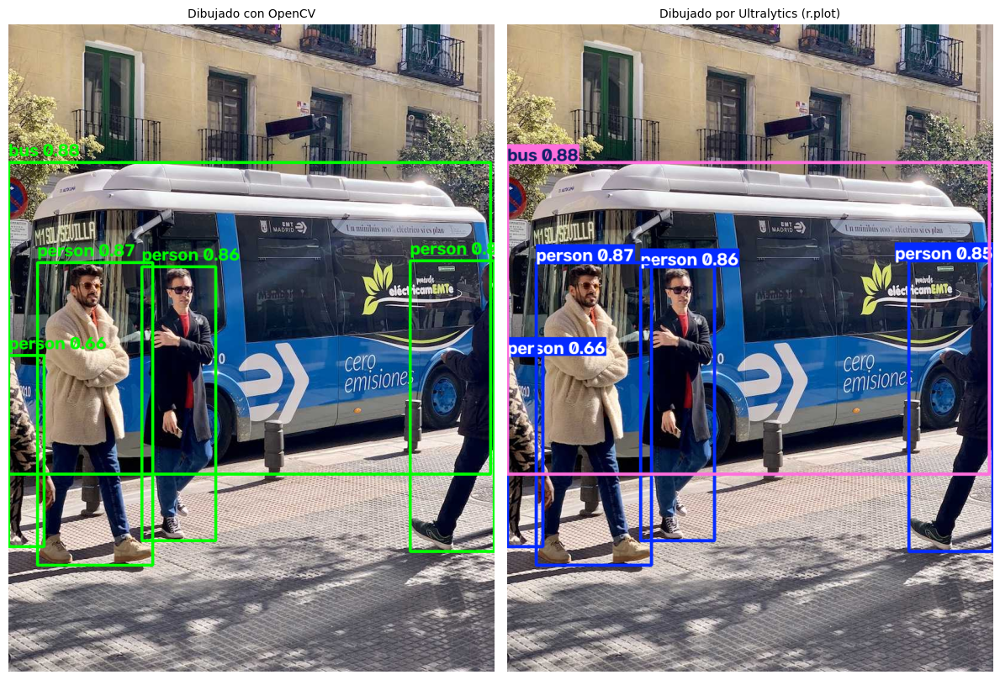

In [3]:
modelo = YOLO('yolo26n.pt')
bus = cv2.imread(ARCHIVOS['bus'])
r = modelo.predict(bus, conf=0.25, device=DEVICE, verbose=False)[0]

tabla = pd.DataFrame({
    'clase': [r.names[int(c)] for c in r.boxes.cls],
    'confianza': r.boxes.conf.cpu().numpy().round(2),
    'caja (x1, y1, x2, y2)': [[int(v) for v in b] for b in r.boxes.xyxy.cpu()],
})
display(tabla)

dibujo = bus.copy()
for (x1, y1, x2, y2), c, p in zip(r.boxes.xyxy.int().tolist(), r.boxes.cls.int().tolist(), r.boxes.conf.tolist()):
    cv2.rectangle(dibujo, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(dibujo, f'{r.names[c]} {p:.2f}', (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
mostrar([dibujo, r.plot()], ['Dibujado con OpenCV', 'Dibujado por Ultralytics (r.plot)'], cols=2, ancho=12)

## **2. Confianza y cajas repetidas**

Para cada objeto, la red propone muchas cajas candidatas. Dos decisiones definen qué se muestra:
* **Confianza mínima:** se descartan las cajas con poca seguridad. Más baja = aparecen más objetos, pero también más errores.
* **Cajas repetidas:** varias cajas pueden marcar el mismo objeto. **YOLO11** las elimina con un paso extra llamado **NMS**, que borra las cajas que se solapan demasiado. **YOLO26** aprendió a no repetir cajas: **ya no necesita NMS**, por eso es más simple y rápido en dispositivos pequeños.

Compara ambos modelos. Baja la **confianza a 0.05** y sube el **solapamiento a 0.95**: ¿qué modelo empieza a repetir cajas?

In [4]:
yolo11 = YOLO('yolo11n.pt')

@interact(confianza=decimal('Confianza mínima', 0.05, 0.9, 0.25), solapamiento=decimal('Solapamiento permitido (IoU)', 0.3, 0.95, 0.7))
def comparar(confianza, solapamiento):
    r11 = yolo11.predict(bus, conf=confianza, iou=solapamiento, device=DEVICE, verbose=False)[0]
    r26 = modelo.predict(bus, conf=confianza, iou=solapamiento, device=DEVICE, verbose=False)[0]
    mostrar([r11.plot(), r26.plot()], [f'YOLO11n (con NMS): {len(r11)} cajas', f'YOLO26n (sin NMS): {len(r26)} cajas'], cols=2, ancho=12)

interactive(children=(FloatSlider(value=0.25, continuous_update=False, description='Confianza mínima', layout=…

## **3. Los límites del modelo de fábrica**

`yolo26n.pt` aprendió **80 clases** del dataset COCO (personas, autos, animales, algunas frutas...). ¿Qué pasa fuera de lo que aprendió?

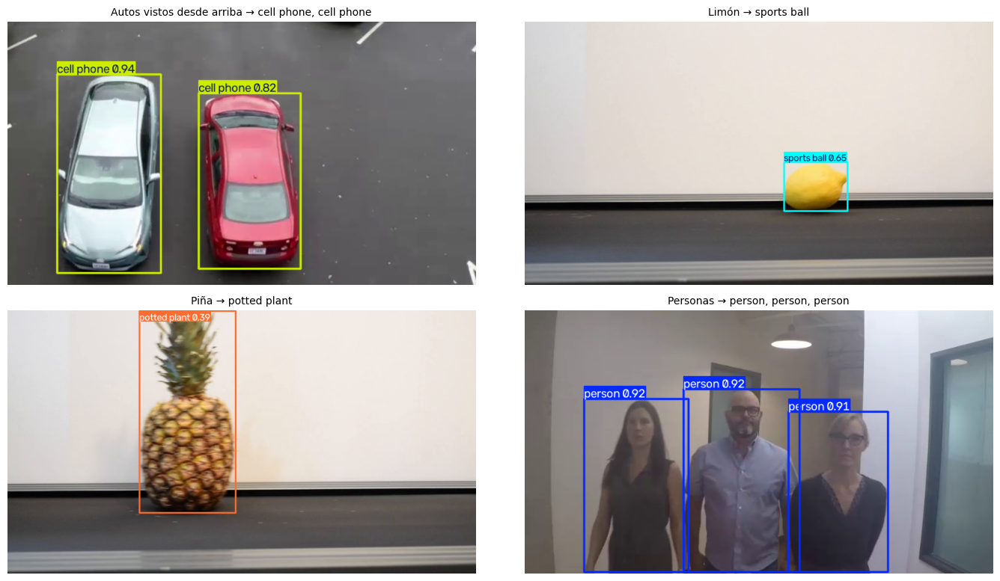

In [5]:
pruebas = [('autos', 208, 'Autos vistos desde arriba'), ('frutas', 1020, 'Limón'), ('frutas', 1260, 'Piña'), ('rostros', 488, 'Personas')]
vistas, titulos = [], []
for video, n, que in pruebas:
    rr = modelo.predict(leer_frame(ARCHIVOS[video], n), conf=0.25, device=DEVICE, verbose=False)[0]
    vistas.append(rr.plot())
    titulos.append(f'{que} → ' + (', '.join(rr.names[int(c)] for c in rr.boxes.cls) or 'nada'))
mostrar(vistas, titulos, cols=2, ancho=14)

* Los **autos vistos desde arriba** se confunden con *cell phone*: casi no hay autos desde ese ángulo en COCO.
* El **limón** aparece como *sports ball* y la **piña** como *vase*: el modelo solo conoce sus 80 clases y elige la "más parecida".
* Detecta cada **person**, pero COCO **no tiene la clase "rostro"**.

Las dos soluciones que veremos: **entrenar con nuestras propias clases** (Parte 3) y usar un **modelo especializado en rostros** (Parte 4).

# **Parte 2 — YOLO + OpenCV**

## **4. OpenCV antes y después del modelo**

YOLO no reemplaza a OpenCV: se complementan.
* **Antes del modelo:** OpenCV **prepara** la imagen (limpiar ruido, recortar una zona, ajustar tamaño).
* **Después del modelo:** OpenCV **usa** las cajas (recortar, contar, dibujar, ocultar, medir).

**Antes:** una cámara con interferencia agrega puntos blancos y negros. Con el valor inicial, YOLO **pierde el bus**. Prueba qué filtro del Taller 1 lo recupera.

In [6]:
def sal_pimienta(img, proporcion, semilla=0):
    sucia, u = img.copy(), np.random.default_rng(semilla).random(img.shape[:2])
    sucia[u < proporcion / 2], sucia[u > 1 - proporcion / 2] = 0, 255
    return sucia

FILTROS_PREVIOS = {'ninguno': lambda x: x, 'gaussiano': lambda x: cv2.GaussianBlur(x, (5, 5), 0), 'mediana': lambda x: cv2.medianBlur(x, 5)}

@interact(ruido=entero('Ruido sal y pimienta (%)', 0, 40, 30, paso=5), filtro=opciones('Filtro antes de YOLO', list(FILTROS_PREVIOS)))
def limpiar_y_detectar(ruido, filtro):
    entrada = FILTROS_PREVIOS[filtro](sal_pimienta(bus, ruido / 100))
    rr = modelo.predict(entrada, conf=0.4, device=DEVICE, verbose=False)[0]
    clases = ', '.join(sorted(rr.names[int(c)] for c in rr.boxes.cls)) or 'nada'
    mostrar([entrada, rr.plot()], [f'Entrada al modelo (filtro: {filtro})', f'{len(rr)} objetos: {clases}'], cols=2, ancho=12)

interactive(children=(IntSlider(value=30, continuous_update=False, description='Ruido sal y pimienta (%)', lay…

**Después:** con las cajas de YOLO, OpenCV **recorta** cada persona (por ejemplo, para pasarla a otro modelo) y la **pixela** para proteger su privacidad.

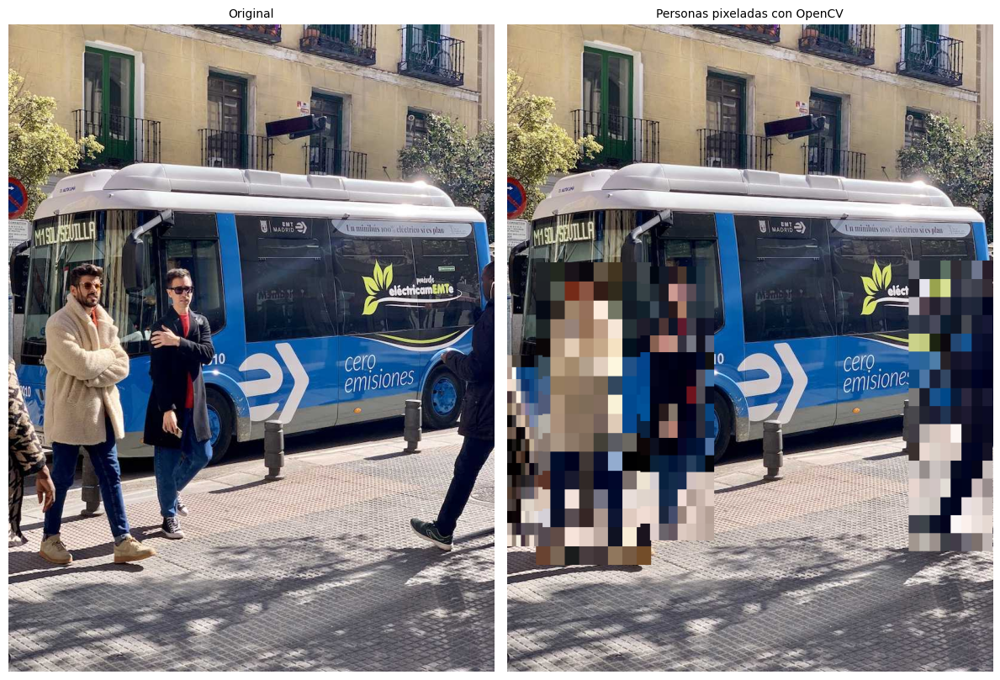

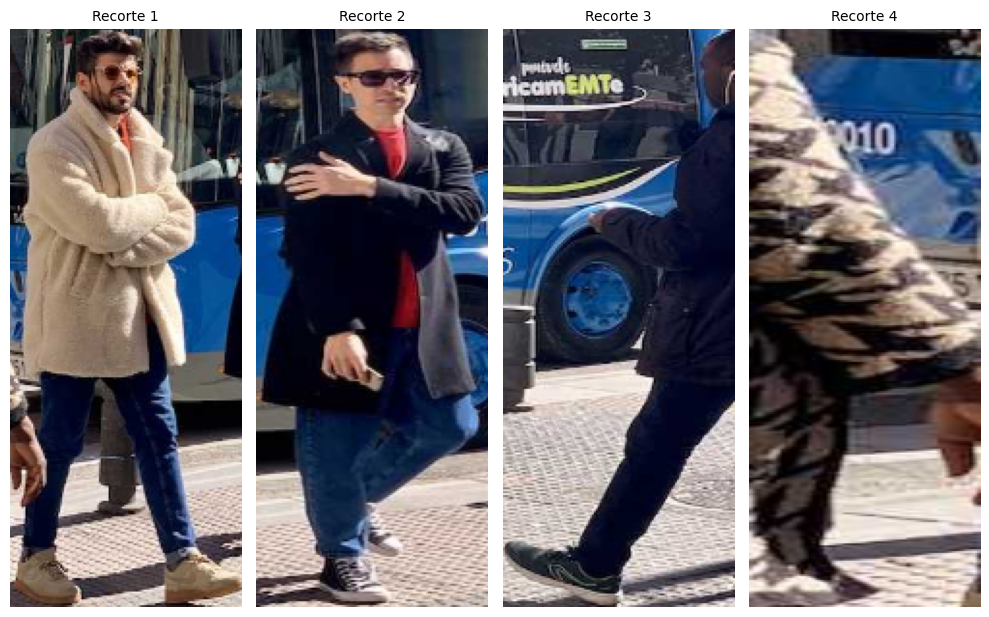

In [7]:
rr = modelo.predict(bus, conf=0.4, device=DEVICE, verbose=False)[0]
personas = [caja for caja, c in zip(rr.boxes.xyxy.int().tolist(), rr.boxes.cls.int().tolist()) if c == 0]   # clase 0 = persona
anonima, recortes = bus.copy(), []
for x1, y1, x2, y2 in personas:
    recortes.append(cv2.resize(bus[y1:y2, x1:x2], (120, 300)))
    zona = anonima[y1:y2, x1:x2]
    anonima[y1:y2, x1:x2] = cv2.resize(cv2.resize(zona, (8, 16)), (x2 - x1, y2 - y1), interpolation=cv2.INTER_NEAREST)
mostrar([bus, anonima], ['Original', 'Personas pixeladas con OpenCV'], cols=2, ancho=12)
mostrar(recortes, [f'Recorte {i + 1}' for i in range(len(recortes))], cols=len(recortes), ancho=10)

# **Parte 3 — Entrenamiento con tus propias imágenes**

## **5. Dataset propio con Roboflow**

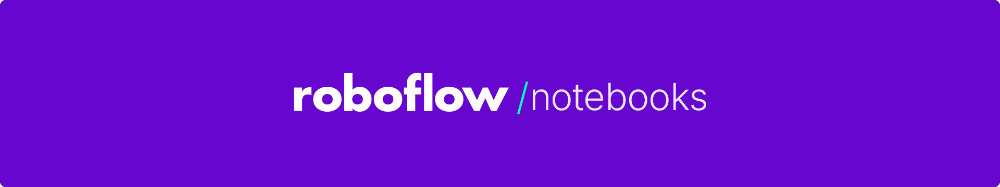

**Roboflow** permite anotar imágenes (dibujar las cajas), aumentar datos y exportarlos listos para YOLO. En [Roboflow Universe](https://universe.roboflow.com/) hay miles de datasets públicos. Usaremos un dataset de **frutas**.

Otros recursos: [Roboflow notebooks](https://github.com/roboflow/notebooks) · [Open Images](https://storage.googleapis.com/openimages/web/index.html)

In [8]:
from roboflow import Roboflow

try:
    from google.colab import userdata
    API_KEY = userdata.get('ROBOFLOW_API_KEY')
except Exception:
    from getpass import getpass
    API_KEY = getpass('Roboflow API key: ')

os.makedirs(f'{HOME}/datasets', exist_ok=True)
%cd {HOME}/datasets
rf = Roboflow(api_key=API_KEY)
dataset = rf.workspace('test-ox2pb').project('fruit-2-1owds').version(2).download('yolov11')   # formato YOLO (sirve para YOLO26)
%cd {HOME}

DATA_YAML = f'{dataset.location}/data.yaml'
print(open(DATA_YAML).read())

/content/datasets
loading Roboflow workspace...
loading Roboflow project...
/content
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5
names: ['Apple', 'Banana', 'Mango', 'Orange', 'Strawberry']

roboflow:
  workspace: test-ox2pb
  project: fruit-2-1owds
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/test-ox2pb/fruit-2-1owds/dataset/2


El archivo `data.yaml` indica dónde están las imágenes de **entrenamiento**, **validación** y **prueba**, y los nombres de las clases. Cada imagen tiene un `.txt` con una línea por objeto: `clase centro_x centro_y ancho alto` (valores entre 0 y 1).

{'train': 1179, 'valid': 79, 'test': 51} ← imágenes por conjunto


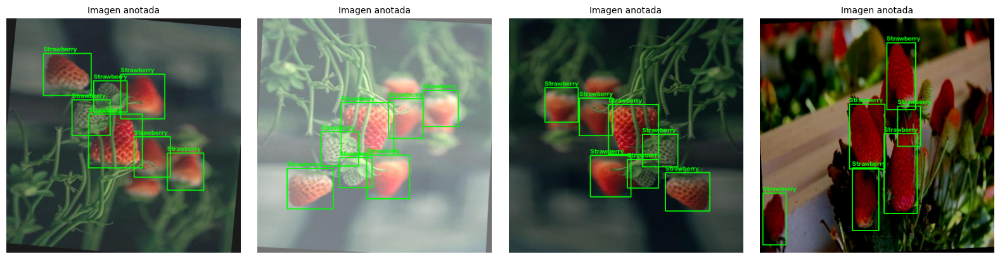

In [9]:
CLASES = yaml.safe_load(open(DATA_YAML))['names']
SPLITS = [s for s in ('train', 'valid', 'test') if os.path.isdir(f'{dataset.location}/{s}')]
print({s: len(glob.glob(f'{dataset.location}/{s}/images/*')) for s in SPLITS}, '← imágenes por conjunto')

def dibujar_etiquetas(ruta_img):
    img = cv2.imread(ruta_img)
    h, w = img.shape[:2]
    ruta_txt = os.path.splitext(ruta_img.replace('/images/', '/labels/'))[0] + '.txt'
    for linea in (open(ruta_txt).read().split('\n') if os.path.exists(ruta_txt) else []):
        p = linea.split()
        if len(p) == 5:
            c, xc, yc, bw, bh = int(p[0]), *map(float, p[1:])
            x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
            cv2.rectangle(img, (x1, y1), (int(x1 + bw * w), int(y1 + bh * h)), (0, 255, 0), 2)
            cv2.putText(img, str(CLASES[c]), (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return img

ejemplos = sorted(glob.glob(f'{dataset.location}/train/images/*'))[:4]
mostrar([cv2.resize(dibujar_etiquetas(p), (400, 400)) for p in ejemplos], ['Imagen anotada'] * len(ejemplos), cols=4)

## **6. Fine-tuning de YOLO26n (en segundo plano)**

No entrenamos desde cero: partimos de `yolo26n.pt`, que ya sabe ver bordes, texturas y formas (**transferencia de aprendizaje**). Solo le enseñamos **nuestras clases**, por eso bastan pocas épocas.

Lanzamos el entrenamiento con la **línea de comandos `yolo`** (como en el taller con YOLO11) como un proceso **en segundo plano**: así el notebook queda libre y, **mientras entrena**, exploramos cómo configurar Ultralytics.

In [10]:
YOLO_CLI = shutil.which('yolo') or os.path.join(os.path.dirname(sys.executable), 'yolo')
TRAIN_DIR = f'{HOME}/runs/frutas'
shutil.rmtree(TRAIN_DIR, ignore_errors=True)          # borrar resultados de entrenamientos anteriores
comando = [YOLO_CLI, 'detect', 'train', 'model=yolo26n.pt', f'data={DATA_YAML}',
           f"epochs={CFG['epochs']}", f"imgsz={CFG['imgsz']}", f"batch={CFG['batch']}", f"fraction={CFG['fraction']}",
           'patience=5', 'workers=2', 'seed=42', f'device={DEVICE}', f'project={HOME}/runs', 'name=frutas', 'exist_ok=True']
print('yolo ' + ' '.join(comando[1:]))              # mismo comando que en la terminal

registro = open('output/entrenamiento.log', 'w')
proceso = subprocess.Popen(comando, stdout=registro, stderr=subprocess.STDOUT)
inicio = time.time()
print('Entrenando en segundo plano... sigue con las celdas de abajo.')

yolo detect train model=yolo26n.pt data=/content/datasets/Fruit-2-2/data.yaml epochs=15 imgsz=640 batch=16 fraction=1.0 patience=5 workers=2 seed=42 device=0 project=/content/runs name=frutas exist_ok=True
Entrenando en segundo plano... sigue con las celdas de abajo.


### Mientras entrena: cómo sacarle provecho a Ultralytics

Todo en Ultralytics se controla con **parámetros** (hay más de 100). Se escriben igual en Python y en la terminal:
* Python: `model.train(data='data.yaml', epochs=50, lr0=0.005)`
* Terminal: `yolo detect train data=data.yaml epochs=50 lr0=0.005`

Los más útiles y sus valores por defecto:

In [11]:
from ultralytics.cfg import get_cfg

defecto = vars(get_cfg())
PARAMETROS = [
    ('Entrenamiento', 'epochs', 'Vueltas completas al dataset'),
    ('Entrenamiento', 'patience', 'Épocas sin mejorar antes de detenerse'),
    ('Entrenamiento', 'batch', 'Imágenes por paso (-1 = automático según la memoria de la GPU)'),
    ('Entrenamiento', 'imgsz', 'Tamaño de entrada; más grande ayuda con objetos pequeños, pero es más lento'),
    ('Entrenamiento', 'freeze', 'Congela las primeras N capas (útil con pocos datos)'),
    ('Entrenamiento', 'cache', 'Guarda las imágenes en memoria para entrenar más rápido'),
    ('Optimización', 'optimizer', 'Algoritmo de ajuste de pesos (auto, SGD, AdamW...)'),
    ('Optimización', 'lr0', 'Tasa de aprendizaje inicial: qué tan grandes son los ajustes'),
    ('Optimización', 'lrf', 'Fracción de lr0 al final del entrenamiento'),
    ('Optimización', 'cos_lr', 'Reduce la tasa de aprendizaje en forma de curva suave'),
    ('Aumento de datos', 'hsv_h', 'Variación de tono (color)'),
    ('Aumento de datos', 'hsv_s', 'Variación de saturación'),
    ('Aumento de datos', 'hsv_v', 'Variación de brillo'),
    ('Aumento de datos', 'degrees', 'Rotación máxima en grados'),
    ('Aumento de datos', 'translate', 'Desplazamiento máximo (fracción de la imagen)'),
    ('Aumento de datos', 'scale', 'Zoom aleatorio (± fracción)'),
    ('Aumento de datos', 'fliplr', 'Probabilidad de espejo horizontal'),
    ('Aumento de datos', 'mosaic', 'Probabilidad de unir 4 imágenes en una'),
    ('Aumento de datos', 'close_mosaic', 'Últimas épocas sin mosaico'),
    ('Predicción', 'conf', 'Confianza mínima (en predicción, por defecto 0.25)'),
    ('Predicción', 'iou', 'Solapamiento máximo entre cajas (solo con NMS)'),
    ('Predicción', 'max_det', 'Máximo de objetos por imagen'),
    ('Predicción', 'classes', 'Filtrar clases, por ejemplo [0] = solo personas'),
    ('Predicción', 'vid_stride', 'En video: procesar 1 de cada N frames'),
]
display(pd.DataFrame([{'grupo': g, 'parámetro': k, 'por defecto': defecto[k], 'para qué sirve': d} for g, k, d in PARAMETROS]))

,grupo,parámetro,por defecto,para qué sirve
0,Entrenamiento,epochs,100,Vueltas completas al dataset
1,Entrenamiento,patience,100,Épocas sin mejorar antes de detenerse
2,Entrenamiento,batch,16,Imágenes por paso (-1 = automático según la me...
3,Entrenamiento,imgsz,640,Tamaño de entrada; más grande ayuda con objeto...
4,Entrenamiento,freeze,None,Congela las primeras N capas (útil con pocos d...
5,Entrenamiento,cache,False,Guarda las imágenes en memoria para entrenar m...
6,Optimización,optimizer,auto,"Algoritmo de ajuste de pesos (auto, SGD, AdamW..."
7,Optimización,lr0,0.01,Tasa de aprendizaje inicial: qué tan grandes s...
8,Optimización,lrf,0.01,Fracción de lr0 al final del entrenamiento
9,Optimización,cos_lr,False,Reduce la tasa de aprendizaje en forma de curv...


#### Aumento de datos: cómo "ve" el modelo tus imágenes al entrenar

En cada época, Ultralytics **modifica las imágenes al azar** (color, rotación, zoom, espejo, mosaico) para que el modelo no memorice y funcione en condiciones distintas. Son operaciones de OpenCV como las del Taller 1. Reprodúcelas con los controles (las cajas se mueven junto con la imagen):

In [12]:
imagenes_train = sorted(glob.glob(f'{dataset.location}/train/images/*'))

def aumentar(img, hsv_h, hsv_s, hsv_v, degrees, scale, translate, fliplr):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + hsv_h * 180) % 180                    # tono
    hsv[..., 1] = np.clip(hsv[..., 1] * (1 + hsv_s), 0, 255)            # saturación
    hsv[..., 2] = np.clip(hsv[..., 2] * (1 - hsv_v), 0, 255)            # brillo
    img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), degrees, 1 + scale)
    M[:, 2] += (translate * w, translate * h)
    img = cv2.warpAffine(img, M, (w, h), borderValue=(114, 114, 114))   # gris = relleno de Ultralytics
    return cv2.flip(img, 1) if fliplr else img

@interact(hsv_h=decimal('hsv_h (tono)', 0, 0.5, 0.0, paso=0.02), hsv_s=decimal('hsv_s (saturación)', -0.9, 0.9, 0.5, paso=0.1),
          hsv_v=decimal('hsv_v (brillo)', 0, 0.9, 0.3, paso=0.1), degrees=entero('degrees (rotación)', -45, 45, 10, paso=5),
          scale=decimal('scale (zoom)', -0.5, 0.5, 0.2, paso=0.1), translate=decimal('translate', 0, 0.3, 0.1),
          fliplr=widgets.Checkbox(value=True, description='fliplr (espejo)'),
          mosaico=widgets.Checkbox(value=False, description='mosaic (4 imágenes)'))
def ver_aumento(hsv_h, hsv_s, hsv_v, degrees, scale, translate, fliplr, mosaico):
    rutas = imagenes_train[:4] if mosaico else imagenes_train[:1]
    piezas = [aumentar(cv2.resize(dibujar_etiquetas(r), (320, 320)), hsv_h, hsv_s, hsv_v, degrees, scale, translate, fliplr) for r in rutas]
    resultado = np.vstack([np.hstack(piezas[:2]), np.hstack(piezas[2:])]) if mosaico else piezas[0]
    original = cv2.resize(dibujar_etiquetas(rutas[0]), (320, 320))
    mostrar([original, resultado], ['Original', 'Como la ve el modelo al entrenar'], cols=2, ancho=10)

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='hsv_h (tono)', layout=Layou…

Ultralytics guarda ejemplos reales de lo que vio el modelo (`train_batch0.jpg`, con mosaico). Ejecuta la celda cuando hayan pasado unos segundos de entrenamiento:

In [13]:
lote = f'{TRAIN_DIR}/train_batch0.jpg'
display(IPyImage(filename=lote, width=700)) if os.path.exists(lote) else print('Aún no está listo: vuelve a ejecutar en unos segundos.')

Aún no está listo: vuelve a ejecutar en unos segundos.


#### Parámetros de predicción

Al usar el modelo también se configura. Prueba en el frame 244 del pasillo (2 personas lejanas):
* **imgsz:** con 160 las personas lejanas desaparecen; más grande = detecta objetos pequeños, pero tarda más.
* **max_det:** limita cuántos objetos se devuelven.
* **classes:** filtra lo que no interesa.

In [14]:
modelo_pred = YOLO('yolo26n.pt')                                  # instancia aparte: classes se recuerda entre llamadas
pasillo = leer_frame(ARCHIVOS['rostros'], 244)

@interact(imgsz=opciones('imgsz', [160, 320, 640, 1280], 640), conf=decimal('conf', 0.05, 0.9, 0.25),
          max_det=entero('max_det', 1, 50, 50), solo_personas=widgets.Checkbox(value=False, description='classes=[0] (solo personas)'))
def predecir(imgsz, conf, max_det, solo_personas):
    rr = modelo_pred.predict(pasillo, imgsz=imgsz, conf=conf, max_det=max_det,
                             classes=[0] if solo_personas else None, device=DEVICE, verbose=False)[0]
    mostrar([rr.plot()], [f'imgsz={imgsz}: {len(rr)} objetos en {sum(rr.speed.values()):.0f} ms'], cols=1, ancho=9)

interactive(children=(Dropdown(description='imgsz', index=2, options=(160, 320, 640, 1280), style=DescriptionS…

#### Guardar tu configuración en un archivo

En lugar de escribir los parámetros cada vez, se guardan en un archivo YAML y se reutilizan:

In [15]:
# ejemplo para un entrenamiento posterior (no se ejecuta ahora)
mi_config = {'epochs': 20, 'imgsz': 640, 'patience': 10, 'optimizer': 'AdamW', 'lr0': 0.002, 'cos_lr': True,
             'hsv_v': 0.5, 'degrees': 10, 'fliplr': 0.5, 'mosaic': 1.0, 'close_mosaic': 10}
with open('output/mi_config.yaml', 'w') as f:
    yaml.safe_dump(mi_config, f, sort_keys=False)
print(open('output/mi_config.yaml').read())

epochs: 20
imgsz: 640
patience: 10
optimizer: AdamW
lr0: 0.002
cos_lr: true
hsv_v: 0.5
degrees: 10
fliplr: 0.5
mosaic: 1.0
close_mosaic: 10



Se usa así (no lo ejecutes ahora, ya hay un entrenamiento en curso):
* Python: `YOLO('yolo26n.pt').train(data=DATA_YAML, cfg='output/mi_config.yaml')`
* Terminal: `yolo detect train data=data.yaml cfg=output/mi_config.yaml`

Otras opciones útiles:
* `resume=True`: continuar un entrenamiento interrumpido desde `last.pt`.
* `freeze=10`: congelar las primeras 10 capas (entrena más rápido; útil con pocos datos).
* `model.tune(data=DATA_YAML, epochs=30, iterations=100)`: **búsqueda automática** de hiperparámetros. Ultralytics entrena muchas veces cambiando los valores y se queda con los mejores. Es muy costoso (100 entrenamientos): para un proyecto, no para la clase.

#### Progreso del entrenamiento

Ejecuta esta celda las veces que quieras para ver cómo avanza:

In [16]:
def progreso():
    csv = f'{TRAIN_DIR}/results.csv'
    estado = 'entrenando...' if proceso.poll() is None else 'terminado'
    if not os.path.exists(csv):
        print('Preparando datos...', estado); return
    df = pd.read_csv(csv)
    df.columns = df.columns.str.strip()
    minutos = (time.time() - inicio) / 60
    restante = minutos / len(df) * (CFG['epochs'] - len(df)) if proceso.poll() is None else 0
    print(f"Época {len(df)} de {CFG['epochs']} · {estado} · {minutos:.1f} min transcurridos · ~{restante:.1f} min restantes")
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    df[['train/box_loss', 'val/box_loss']].plot(ax=axes[0], title='Error al ubicar cajas (debe bajar)')
    df[['metrics/mAP50(B)', 'metrics/mAP50-95(B)']].plot(ax=axes[1], title='Calidad mAP (debe subir)')
    plt.tight_layout(); plt.show()

progreso()

Preparando datos... entrenando...


Sigue el entrenamiento **época a época** hasta que termine (si ya terminó, muestra el resumen de inmediato). La pérdida (`box_loss`, `cls_loss`) debería bajar y el mAP subir:

época   min  box_loss  cls_loss precisión  recall  mAP50 mAP50-95
    1   0.6     1.379     2.885      0.36    0.56   0.44     0.28
    2   1.0     1.330     1.776      0.56    0.58   0.56     0.37
    3   1.3     1.294     1.457      0.54    0.57   0.57     0.36
    4   1.6     1.291     1.425      0.56    0.65   0.62     0.43
    5   2.0     1.269     1.297      0.64    0.65   0.68     0.45
    6   2.3     1.242     1.163      0.76    0.69   0.75     0.51
    7   2.6     1.136     1.050      0.72    0.63   0.71     0.49
    8   2.8     1.138     0.963      0.79    0.65   0.76     0.53
    9   3.1     1.089     0.869      0.71    0.75   0.78     0.54
   10   3.4     1.066     0.782      0.78    0.73   0.80     0.57
   11   3.7     0.991     0.748      0.82    0.74   0.83     0.61
   12   4.0     0.999     0.668      0.84    0.74   0.83     0.60
   13   4.2     0.983     0.648      0.83    0.73   0.82     0.60
   14   4.6     0.948     0.621      0.86    0.72   0.83     0.62
   15   4.

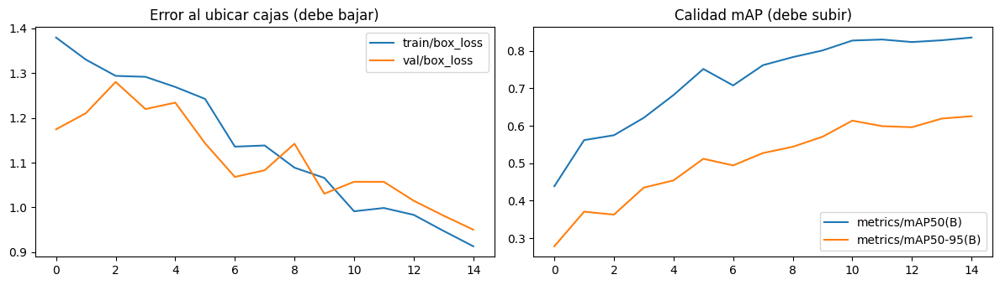

In [17]:
csv, mostradas = f'{TRAIN_DIR}/results.csv', 0
print(f"{'época':>5} {'min':>5} {'box_loss':>9} {'cls_loss':>9} {'precisión':>9} {'recall':>7} {'mAP50':>6} {'mAP50-95':>8}")
while True:
    terminado = proceso.poll() is not None
    if os.path.exists(csv):
        df = pd.read_csv(csv)
        df.columns = df.columns.str.strip()
        for _, f in df.iloc[mostradas:].iterrows():                    # solo las épocas nuevas
            print(f"{int(f['epoch']):>5} {(time.time() - inicio) / 60:>5.1f} {f['train/box_loss']:>9.3f} {f['train/cls_loss']:>9.3f} "
                  f"{f['metrics/precision(B)']:>9.2f} {f['metrics/recall(B)']:>7.2f} {f['metrics/mAP50(B)']:>6.2f} {f['metrics/mAP50-95(B)']:>8.2f}", flush=True)
        mostradas = len(df)
    if terminado:
        break
    time.sleep(5)

registro.close()
BEST = f'{TRAIN_DIR}/weights/best.pt'
print(f'\nEntrenamiento terminado en {(time.time() - inicio) / 60:.1f} min.' if os.path.exists(BEST) else open('output/entrenamiento.log').read()[-2000:])
progreso()

> **Plan B** (sin GPU o si se desconecta la sesión): carga un modelo ya entrenado desde Drive y continúa con la evaluación.
> ```python
> from google.colab import drive; drive.mount('/content/drive')
> BEST = '/content/drive/MyDrive/Taller2/best.pt'
> TRAIN_DIR = os.path.dirname(os.path.dirname(BEST))
> ```

## **7. Evaluación: ¿qué tan bien detecta?**

Evaluamos con las imágenes de **prueba**, que el modelo nunca vio. Primero, cómo se decide si una detección es correcta:
* **IoU (solapamiento):** cuánto coincide la caja predicha con la caja real (0 = nada, 1 = idénticas). Una detección cuenta como **acierto** si su IoU con una caja real de la misma clase supera un umbral (por ejemplo 0.5).
* Con eso cada caja es un **verdadero positivo** (acierto), un **falso positivo** (detectó algo que no estaba o con la clase equivocada) o un **falso negativo** (un objeto real que no detectó).

**Ejemplo:** en las imágenes de prueba hay **10 naranjas**. El modelo dibuja **8 cajas de naranja**: 6 están bien y 2 son errores (una manzana y un trozo de fondo). Se le escaparon 4 naranjas.

| Métrica | Pregunta que responde | En el ejemplo |
|---|---|---|
| **Precisión** | De lo que detectó, ¿cuánto era correcto? (pocas falsas alarmas) | 6 de 8 → **75 %** |
| **Recall** (sensibilidad) | De lo que había, ¿cuánto encontró? (pocos objetos perdidos) | 6 de 10 → **60 %** |
| **F1** | Equilibrio entre precisión y recall en un solo número | ≈ **67 %** |
| **AP** (precisión promedio) | Calidad de **una clase** considerando todos los umbrales de confianza (área bajo la curva precisión-recall) | Se calcula con la curva |
| **mAP50** | Promedio del AP de **todas las clases**, con IoU ≥ 0.5 | — |
| **mAP50-95** | Lo mismo, pero exigiendo cajas cada vez más precisas (IoU de 0.5 a 0.95): la métrica más estricta | — |

**¿Y la *accuracy* (exactitud)?** Es el porcentaje de respuestas correctas sobre el total. Se usa en **clasificación** (una etiqueta por imagen, como el clasificador de la Sección 10 o `yolo26n-cls`), pero **no en detección**: en una imagen hay infinitas zonas de "fondo" correctamente vacías que no se pueden contar. Por eso los detectores se evalúan con precisión, recall y mAP.

**Precisión vs recall dependen del umbral de confianza:** si lo subes, el modelo se equivoca menos (más precisión) pero deja escapar más objetos (menos recall). La elección depende del problema: en una alarma de seguridad importa no perder a nadie (recall); en un control de calidad, no rechazar piezas buenas (precisión).

In [18]:
best = YOLO(BEST)
split = 'test' if 'test' in SPLITS else 'val'
metricas = best.val(data=DATA_YAML, split=split, device=DEVICE, plots=True, project=f'{HOME}/runs', name='evaluacion', exist_ok=True)
EVAL_DIR = str(metricas.save_dir)

filas = []
for i, c in enumerate(metricas.box.ap_class_index):
    p, rc, ap50, ap = metricas.box.class_result(i)
    f1 = 2 * p * rc / (p + rc) if p + rc else 0
    filas.append({'clase': metricas.names[int(c)], 'precisión': p, 'recall': rc, 'F1': f1, 'AP50': ap50, 'AP50-95': ap})
display(pd.DataFrame(filas).round(2).sort_values('AP50-95'))
print(f'Global → precisión: {metricas.box.mp:.2f} | recall: {metricas.box.mr:.2f} | mAP50: {metricas.box.map50:.2f} | mAP50-95: {metricas.box.map:.2f}')

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1937.6±474.4 MB/s, size: 57.4 KB)
val: Scanning /content/datasets/Fruit-2-2/test/labels.cache... 51 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 51/51 8.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.6it/s 2.5s
                   all         51        247      0.851      0.786      0.874      0.663
                 Apple          7         59      0.961      0.833      0.941      0.731
                Banana         16         65       0.91        0.8      0.889      0.667
                 Mango         13         51      0.898      0.627      0.755      0.646
                Orange          7         29      0.513      0.793       0.82      0.667
            Strawberry         10        

,clase,precisión,recall,F1,AP50,AP50-95
4,Strawberry,0.97,0.88,0.92,0.97,0.61
2,Mango,0.90,0.63,0.74,0.75,0.65
3,Orange,0.51,0.79,0.62,0.82,0.67
1,Banana,0.91,0.80,0.85,0.89,0.67
0,Apple,0.96,0.83,0.89,0.94,0.73


Global → precisión: 0.85 | recall: 0.79 | mAP50: 0.87 | mAP50-95: 0.66


**¿Qué clase tiene el peor resultado? ¿El problema es de precisión (falsas alarmas) o de recall (objetos perdidos)?**

### Matriz de confusión

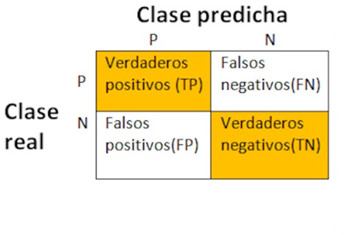

En detección la matriz tiene una fila y una columna extra, **background** (fondo):
* **Columna background:** objetos reales que el modelo **no encontró**.
* **Fila background:** detecciones donde **no había nada**.

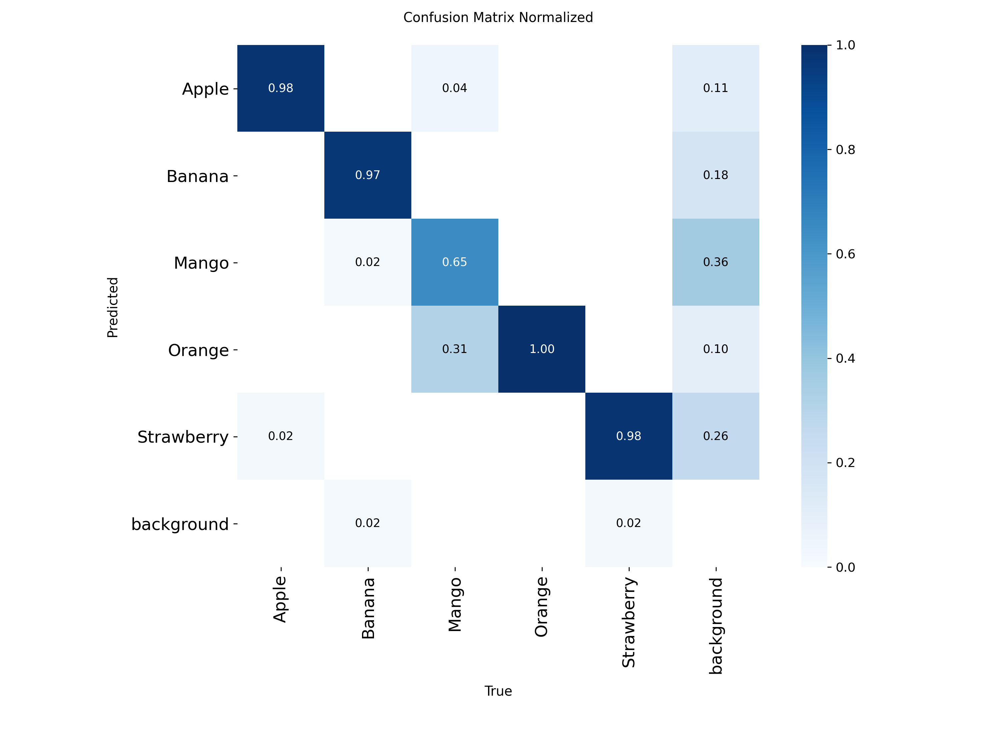

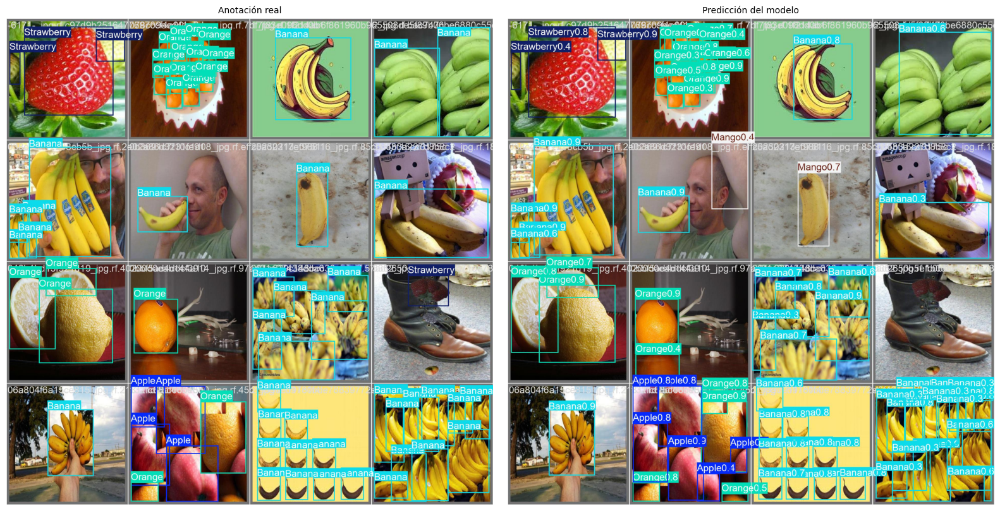

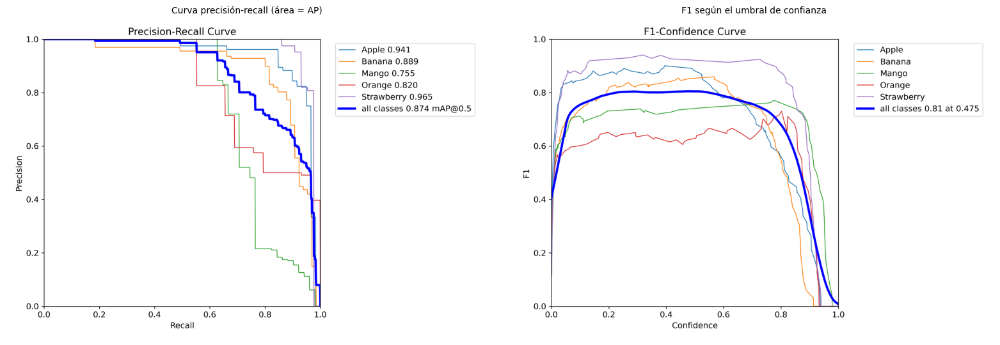

In [19]:
display(IPyImage(filename=f'{EVAL_DIR}/confusion_matrix_normalized.png', width=600))
lotes = [f'{EVAL_DIR}/val_batch0_labels.jpg', f'{EVAL_DIR}/val_batch0_pred.jpg']
if all(os.path.exists(p) for p in lotes):
    mostrar([cv2.imread(p) for p in lotes], ['Anotación real', 'Predicción del modelo'], cols=2, ancho=16)

# curvas: precisión-recall (el área bajo cada curva es el AP) y F1 según el umbral de confianza
curvas = [f'{EVAL_DIR}/BoxPR_curve.png', f'{EVAL_DIR}/BoxF1_curve.png']
if all(os.path.exists(p) for p in curvas):
    mostrar([cv2.imread(p) for p in curvas], ['Curva precisión-recall (área = AP)', 'F1 según el umbral de confianza'], cols=2, ancho=16)

## **8. Antes vs después del entrenamiento**

Volvemos a la banda transportadora: modelo de fábrica (COCO) contra nuestro modelo entrenado.

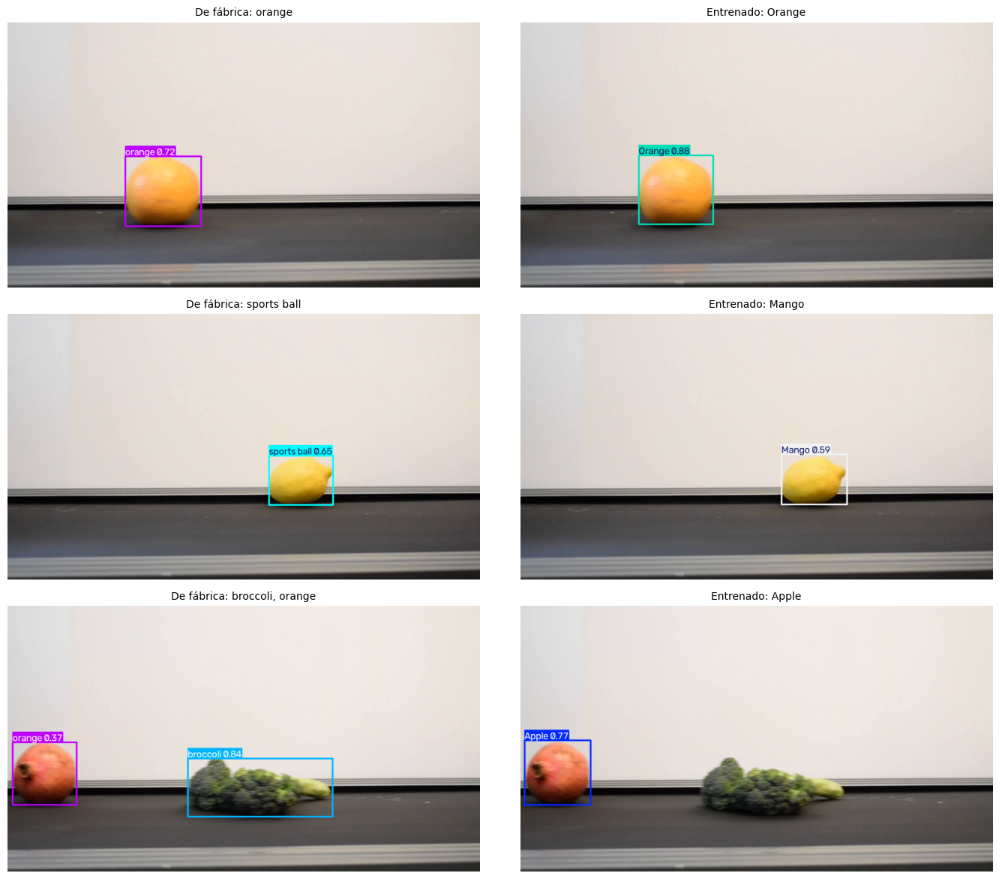

In [20]:
vistas, titulos = [], []
for n in (900, 1020, 3180):
    frame = leer_frame(ARCHIVOS['frutas'], n)
    for nombre, m in (('De fábrica', modelo), ('Entrenado', best)):
        rr = m.predict(frame, conf=0.25, device=DEVICE, verbose=False)[0]
        vistas.append(rr.plot())
        titulos.append(f'{nombre}: ' + (', '.join(rr.names[int(c)] for c in rr.boxes.cls) or 'nada'))
mostrar(vistas, titulos, cols=2, ancho=14)

**Ojo:** el modelo entrenado solo conoce las clases **de su dataset**. Si una fruta no estaba en las imágenes de entrenamiento, la confundirá con la más parecida. **Los datos definen lo que el modelo puede ver.**

### Llevar el modelo a producción: exportar

`export` convierte el modelo a otros formatos para usarlo **sin PyTorch**: ONNX (cualquier computador, incluso con `cv2.dnn`), TensorRT (GPU NVIDIA), OpenVINO (procesadores Intel), TFLite (celulares), entre otros.

In [21]:
ruta_onnx = best.export(format='onnx', imgsz=CFG['imgsz'])
modelo_onnx = YOLO(ruta_onnx, task='detect')
frame = leer_frame(ARCHIVOS['frutas'], 900)
for nombre, m in [('PyTorch (.pt)', best), ('ONNX (.onnx)', modelo_onnx)]:
    m.predict(frame, imgsz=CFG['imgsz'], device='cpu', verbose=False)                         # calentamiento
    tiempos = [sum(m.predict(frame, imgsz=CFG['imgsz'], device='cpu', verbose=False)[0].speed.values()) for _ in range(5)]
    print(f'{nombre:15s} → {np.mean(tiempos):.0f} ms por imagen en CPU')

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/content/runs/frutas/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 9, 8400) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 1.6s, saved as '/content/runs/frutas/weights/best.onnx' (9.4 MB)

Export complete (1.9s)
Results saved to /content/runs/frutas/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs/frutas/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/runs/frutas/weights/best.onnx imgsz=640 data=/content/datasets/Fruit-2-2/data.yaml 
Visualize:       https://netron.app
PyTorch (.pt)   → 59 ms por imagen en CPU
Loading /content/runs/frutas/weights/best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.0 with CPUExe

# **Parte 4 — Rostros y expresiones faciales**

## **9. Detección de rostros con puntos clave**

COCO no tiene la clase "rostro", así que usamos **YOLO26n-face**: un YOLO26 entrenado por la comunidad con miles de rostros ([akanametov/yolo-face](https://github.com/akanametov/yolo-face)). Además de la caja, entrega **5 puntos clave**: ojos, nariz y comisuras de la boca.

Compáralo con el detector de OpenCV (Viola-Jones) del Taller 1 en los mismos frames:

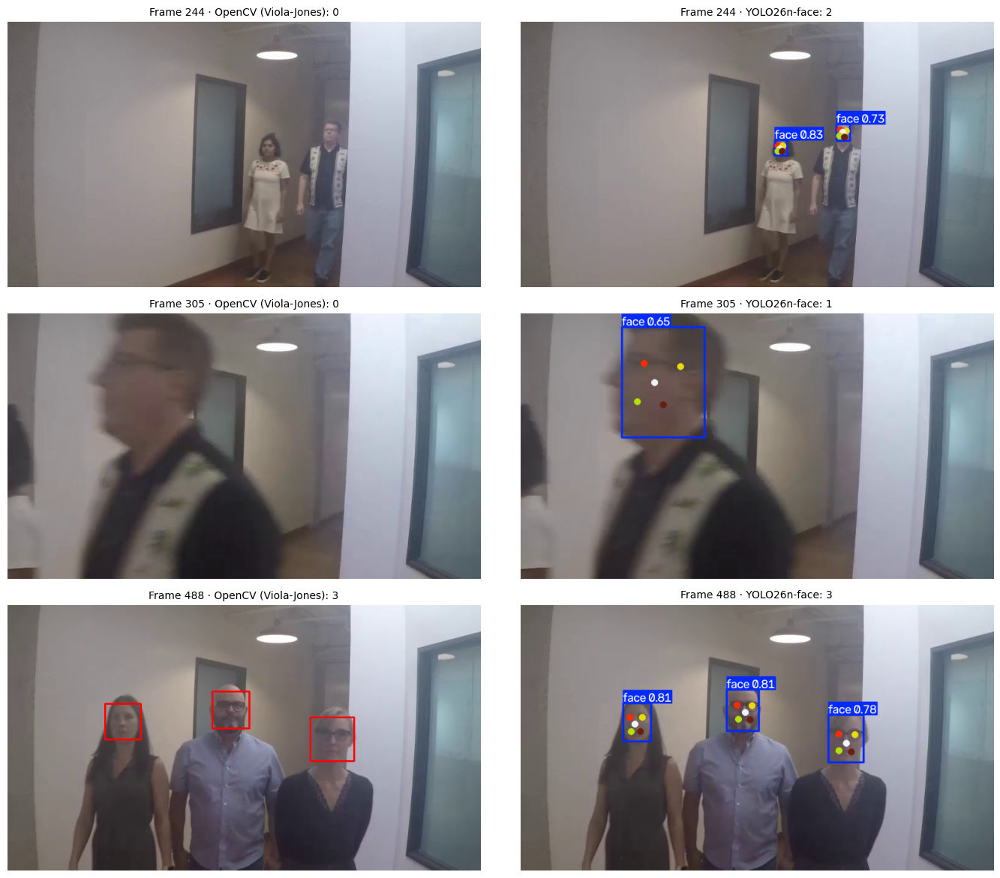

In [22]:
detector_rostros = YOLO(ARCHIVOS['yolo_face'])
haar = cv2.CascadeClassifier(ARCHIVOS['haar'])

vistas, titulos = [], []
for n in (244, 305, 488):
    frame = leer_frame(ARCHIVOS['rostros'], n)
    cajas_haar = haar.detectMultiScale(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    vista_haar = frame.copy()
    for (x, y, w, h) in cajas_haar:
        cv2.rectangle(vista_haar, (x, y), (x + w, y + h), (0, 0, 255), 2)
    rr = detector_rostros.predict(frame, conf=0.4, device=DEVICE, verbose=False)[0]
    vistas += [vista_haar, rr.plot()]
    titulos += [f'Frame {n} · OpenCV (Viola-Jones): {len(cajas_haar)}', f'Frame {n} · YOLO26n-face: {len(rr)}']
mostrar(vistas, titulos, cols=2, ancho=14)

YOLO26n-face encuentra los rostros **pequeños** (frame 244) y **de perfil** (frame 305) que OpenCV pierde, y marca los **5 puntos clave** de cada uno.

## **10. Expresiones faciales: YOLO + OpenCV + un segundo modelo**

Para reconocer la expresión unimos todo lo aprendido en un solo proceso:

| Paso | Herramienta | Qué hace |
|---|---|---|
| 1 | **YOLO26n-face** | Encuentra cada rostro y sus 5 puntos clave |
| 2 | **OpenCV** | Usa los puntos clave para **enderezar** el rostro y llevarlo a 112×112 (ojos y boca siempre en el mismo lugar) |
| 3 | **Modelo de expresiones** (OpenCV Zoo) | Clasifica 7 expresiones: enojo, asco, miedo, felicidad, neutral, tristeza y sorpresa |

El modelo de expresiones es una red **MobileFaceNet** del [OpenCV Model Zoo](https://github.com/opencv/opencv_zoo/tree/main/models/facial_expression_recognition) (licencia Apache 2.0) y se ejecuta con el módulo `cv2.dnn` de OpenCV.

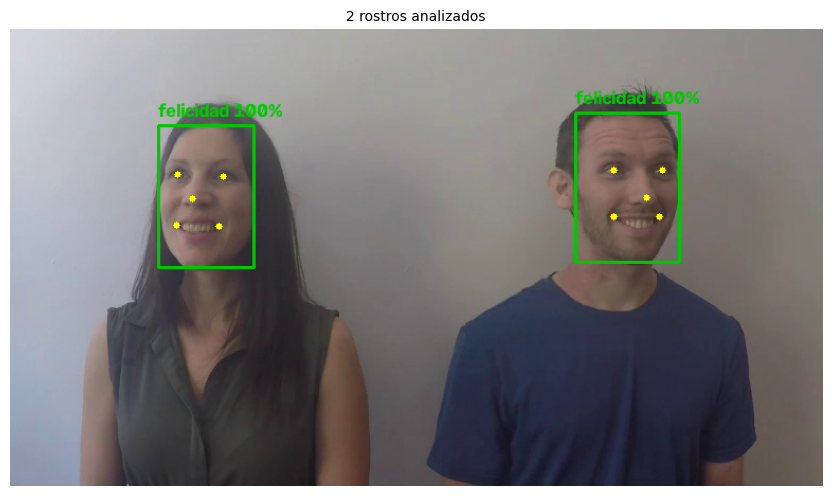

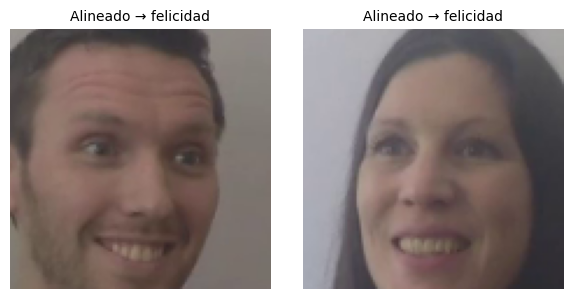

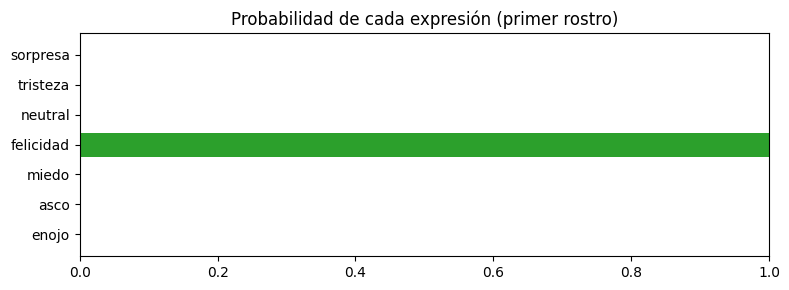

In [23]:
red_expresion = cv2.dnn.readNet(ARCHIVOS['expresion'])
EXPRESIONES = ['enojo', 'asco', 'miedo', 'felicidad', 'neutral', 'tristeza', 'sorpresa']
COLORES = {'felicidad': (0, 200, 0), 'neutral': (200, 200, 200), 'sorpresa': (0, 200, 255), 'tristeza': (255, 120, 0),
           'enojo': (0, 0, 255), 'asco': (0, 120, 120), 'miedo': (200, 0, 200)}
# posición de ojos, nariz y boca en un rostro alineado de 112x112
PLANTILLA = np.float32([[38.29, 51.70], [73.53, 51.50], [56.03, 71.74], [41.55, 92.37], [70.73, 92.20]])

def analizar_rostros(img, conf=0.4):
    """-> lista de rostros con caja, puntos, recorte alineado, expresión y probabilidades."""
    r = detector_rostros.predict(img, conf=conf, device=DEVICE, verbose=False)[0]               # paso 1
    rostros = []
    for caja, puntos in zip(r.boxes.xyxy.int().tolist(), r.keypoints.xy.cpu().numpy()):
        M, _ = cv2.estimateAffinePartial2D(puntos.astype(np.float32), PLANTILLA)                  # paso 2
        alineado = cv2.warpAffine(img, M, (112, 112))
        x = (cv2.cvtColor(alineado, cv2.COLOR_BGR2RGB).astype(np.float32) / 255 - 0.5) / 0.5
        red_expresion.setInput(cv2.dnn.blobFromImage(x))                                          # paso 3
        logits = red_expresion.forward()[0]
        prob = np.exp(logits - logits.max()); prob /= prob.sum()
        rostros.append({'caja': caja, 'puntos': puntos, 'alineado': alineado,
                        'expresion': EXPRESIONES[int(prob.argmax())], 'prob': prob})
    return rostros

def dibujar_rostros(img, rostros):
    vista = img.copy()
    for f in rostros:
        x1, y1, x2, y2 = f['caja']
        color = COLORES[f['expresion']]
        cv2.rectangle(vista, (x1, y1), (x2, y2), color, 2)
        cv2.putText(vista, f"{f['expresion']} {f['prob'].max():.0%}", (x1, y1 - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
        for px, py in f['puntos'].astype(int):
            cv2.circle(vista, (px, py), 3, (0, 255, 255), -1)
    return vista

frame = leer_frame(ARCHIVOS['emociones'], 900)
rostros = analizar_rostros(frame)
mostrar([dibujar_rostros(frame, rostros)] , [f'{len(rostros)} rostros analizados'], cols=1, ancho=9)
mostrar([f['alineado'] for f in rostros], [f"Alineado → {f['expresion']}" for f in rostros], cols=len(rostros), ancho=6)

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(EXPRESIONES, rostros[0]['prob'], color='tab:green'); ax.set_xlim(0, 1)
ax.set_title('Probabilidad de cada expresión (primer rostro)'); plt.tight_layout(); plt.show()

La misma idea aplicada a un video: las dos personas pasan de **neutral** a **sorpresa** y luego a **felicidad**.

In [24]:
cuadros = [dibujar_rostros(f, analizar_rostros(f)) for f in (leer_frame(ARCHIVOS['emociones'], n) for n in range(830, 975, 3))]
guardar_gif(cuadros, 'output/expresiones.gif', ms=120, ancho=640)

Output hidden; open in https://colab.research.google.com to view.

## **11. Prueba con tu cámara**

Ejecuta la celda, permite el acceso a la cámara y pulsa **Capturar**. Prueba distintas caras: sonríe, sorpréndete, pon cara seria o triste. (Si prefieres, cambia `USAR_CAMARA = False` para subir una foto.)

> Solo con tu consentimiento. La imagen se procesa en tu sesión de Colab y no se guarda en ningún otro lugar.

In [ ]:
USAR_CAMARA = True

def tomar_foto(ruta='output/mi_foto.jpg', calidad=0.9):
    from google.colab.output import eval_js
    display(HTML("""<script>
    async function tomarFoto(calidad) {
      const div = document.createElement('div');
      const boton = document.createElement('button'); boton.textContent = 'Capturar';
      const video = document.createElement('video'); video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div); div.appendChild(video); div.appendChild(boton);
      video.srcObject = stream; await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => boton.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth; canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop(); div.remove();
      return canvas.toDataURL('image/jpeg', calidad);
    }</script>"""))
    datos = eval_js(f'tomarFoto({calidad})')
    with open(ruta, 'wb') as f:
        f.write(b64decode(datos.split(',')[1]))
    return ruta

try:
    if USAR_CAMARA:
        foto = cv2.imread(tomar_foto())
    else:
        from google.colab import files
        subida = files.upload()
        foto = cv2.imdecode(np.frombuffer(list(subida.values())[0], np.uint8), cv2.IMREAD_COLOR)
except ImportError:
    foto = leer_frame(ARCHIVOS['emociones'], 858)                 # fuera de Colab: frame de ejemplo
    print('Fuera de Colab: se usa un frame del video de ejemplo.')

rostros = analizar_rostros(foto)
mostrar([dibujar_rostros(foto, rostros)], [f'{len(rostros)} rostro(s)'], cols=1, ancho=8)
for i, f in enumerate(rostros):
    print(f'Rostro {i + 1}: ' + ', '.join(f'{e} {p:.0%}' for e, p in sorted(zip(EXPRESIONES, f['prob']), key=lambda t: -t[1])[:3]))

**Para discutir:**
* Una **expresión** no es lo mismo que una **emoción**: alguien puede sonreír estando nervioso. El modelo solo ve la cara.
* El modelo aprendió con fotos de un tipo de personas, luces y ángulos: ¿funciona igual con todas las personas?
* **Regulación:** en la Unión Europea, el AI Act prohíbe usar reconocimiento de emociones en **lugares de trabajo y centros educativos** (salvo por razones médicas o de seguridad). En Ecuador, los datos biométricos son **datos sensibles** según la Ley Orgánica de Protección de Datos Personales.

# **Cierre**

**Lo que te llevas:**
1. YOLO mira la imagen **una sola vez**; la **confianza** decide qué se muestra y YOLO26 ya no necesita eliminar cajas repetidas.
2. **OpenCV y YOLO se complementan:** OpenCV limpia la imagen antes y usa las cajas después (recortar, ocultar, alinear).
3. Con **fine-tuning** un modelo aprende **tus clases** con pocas imágenes y pocas épocas. Sus **hiperparámetros** (épocas, tasa de aprendizaje, aumento de datos, tamaño de imagen) se configuran en Python, en la terminal o en un archivo YAML.
4. El proceso **detectar → alinear con puntos clave → clasificar** permite reconocer expresiones. **Cambiando el último modelo** por uno de reconocimiento facial, el mismo proceso reconoce **quién es** la persona: ese es tu proyecto final.

### Reto
1. En la Sección 2, ¿con qué combinación de confianza y solapamiento YOLO11 repite más cajas?
2. En la Sección 4, ¿desde qué porcentaje de ruido YOLO pierde el bus sin filtro?
3. Entrena con otro dataset de [Roboflow Universe](https://universe.roboflow.com/) de tu área y compara las métricas.
4. Entrena de nuevo con `output/mi_config.yaml` (más épocas, otros aumentos de datos) y compara el mAP con tu primer modelo.
5. **(Proyecto final)** Lleva el análisis de expresiones a video con `vid_stride` y tu cámara.